In [1]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score
)
import numpy as np
import tensorflow as tf
from keras import layers
import pandas as pd

def evaluate_model(y_true, y_pred, scores, time, threshold=0.2, model_name="Model"):
    """
    Evaluates a model and returns metrics formatted for copy-pasting.
    
    Parameters:
        y_true (np.array): Ground truth labels (0=normal, 1=anomaly).
        scores (np.array): Anomaly scores (lower = more anomalous).
        threshold (float): Threshold for anomaly decision.
        model_name (str): Name of the model.
        
    Returns:
        dict: Dictionary of metrics (can print or format for LaTeX).
    """

    precision = precision_score(y_true, y_pred, zero_division=0)
    accuracy = accuracy_score(y_true, y_pred)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    auroc = roc_auc_score(y_true, scores)

    cm = confusion_matrix(y_true, y_pred)
    clf_report = classification_report(y_true, y_pred, digits=2)

    result = {
        "Model": model_name,
        "Precision": f"{precision:.3f}",
        "Accuracy": f"{accuracy:.3f}",
        "Recall": f"{recall:.3f}",
        "F1-Score": f"{f1:.3f}",
        "Matrix": f"TP={cm[1,1]}, FP={cm[0,1]}, FN={cm[1,0]}, TN={cm[0,0]}",
        "AUROC": f"{auroc:.3f}",
        "Data Loading + Inference Time (s)": f"{time:.4f}s",
        "Clf Report": clf_report.strip()
    }

    return result


2025-08-13 09:52:16.070965: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-08-13 09:52:16.148810: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
@tf.keras.utils.register_keras_serializable()
class AnomalyDetector(tf.keras.Model):
    def __init__(self, **kwargs):
        super(AnomalyDetector, self).__init__(**kwargs)
        self.encoder = tf.keras.Sequential([
          # layers.Dense(16, activation="relu"),
          # # Model was overfitting so add dropout layers
          # layers.Dropout(0.2),
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(4, activation="relu")

            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(8, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU()
        ])
    
        self.decoder = tf.keras.Sequential([

            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(24)
            
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(16, activation="relu"),
          # layers.Dropout(0.1),
          # layers.Dense(24)
        ])
      
    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

    def get_config(self):
        # Return config dictionary; empty because no constructor args
        base_config = super(AnomalyDetector, self).get_config()
        return base_config

    @classmethod
    def from_config(cls, config):
        return cls(**config)

In [3]:
# import pandas as pd

# cae_model = tf.keras.models.load_model(
#     "Models/8f_cae_model.keras",
#     custom_objects={"AnomalyDetector": AnomalyDetector}
# )

In [4]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

In [5]:
transformed_testing_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

In [6]:
transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

In [8]:
from qiskit.qpy import load

model_name = "8f_qae_dense_ra2_10k"
model_path = "Models/QAE/First_N/"

with open(f"{model_path + model_name}/ae.qpy", "rb") as f:
    ae = load(f)[0]  # returns a list of circuits
    
# input_names = np.load(f"{model_name}/input_param_names.npy", allow_pickle=True)
weight_names = np.load(f"{model_path + model_name}/weight_param_names.npy", allow_pickle=True)
# input_params = [p for p in qc.parameters if p.name in input_names]
weight_params = [p for p in ae.parameters if p.name in weight_names]
trained_params = np.load(f"{model_path + model_name}/trained_parameters.npy")

# selected_features = np.load(f"{model_path + model_name}/selected_features.npy")


In [9]:
import time
from sklearn.preprocessing import MinMaxScaler

start_time = time.time()

# reduced_testing_data = cae_model.encoder(testing_data)
reduced_testing_data = testing_data
# reduced_testing_data = np.array(testing_data)[:, selected_features]

# DEBUG
# sample_idx = 10  # pick any row index you want to check

# full_row = np.array(testing_data[sample_idx])
# reduced_row = reduced_testing_data[sample_idx]
# selected_cols = selected_features

# print("Selected feature indices:", selected_cols)
# print("Full data row (selected features):", full_row[selected_cols])
# print("Reduced data row:", reduced_row)

# # Check if they are equal (within floating point tolerance)
# if np.allclose(full_row[selected_cols], reduced_row):
#     print("✅ Rows match perfectly for selected features!")
# else:
#     print("❌ Rows do NOT match!")
# DEBUG

# --- SCALE TO [0, π] ---
# scaler = MinMaxScaler(feature_range=(0, np.pi))
# scaled_testing_data = scaler.fit_transform(reduced_testing_data)
scaled_testing_data = reduced_testing_data

# Loading for Threshold
# reduced_normal_training_data = cae_model.encoder(normal_training_data)
reduced_normal_training_data = normal_training_data
# reduced_normal_training_data = np.array(training_data)[:, selected_features]
# scaler = MinMaxScaler(feature_range=(0, np.pi))
# scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)
scaled_normal_training_data = reduced_normal_training_data

# Loading for Validation
# reduced_validation_data = cae_model.encoder(validation_data)
reduced_validation_data = validation_data
# reduced_validation_data = np.array(validation_data)[:, selected_features]
# scaler = MinMaxScaler(feature_range=(0, np.pi))
# scaled_validation_data = scaler.fit_transform(reduced_validation_data)
scaled_validation_data = reduced_validation_data

In [10]:
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_aer.primitives import Sampler
from qiskit import QuantumCircuit

# sampler = Sampler(backend_options={"device": "GPU", "method": "statevector"})
sampler = Sampler()

# Constants
num_latent = 2
num_trash = 2
total_qubits = num_latent + 2 * num_trash + 1  # encoding + reference + auxiliary

# Step 2: Dummy base circuit (will be composed with encoding later)
# Needed just for QNN init. Actual data circuits will be composed separately.
dummy_encoding = QuantumCircuit(total_qubits)
qc_full = dummy_encoding.compose(ae)

# Step 3: Define the Sampler QNN
qnn = SamplerQNN(
    circuit=qc_full,
    input_params=[],                     # No input parameters — encoding is done externally
    weight_params=weight_params,         # Only train the parameters of the AE
    output_shape=2,                      # Binary outcome (0 or 1 from SWAP test)
    interpret=lambda x: x,               # Identity function, optional
    sampler=sampler
)

/tmp/ipykernel_4999/2517850425.py:20: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(


In [11]:
from qiskit.circuit import QuantumCircuit, ParameterVector
from qiskit.circuit.library import EfficientSU2, RealAmplitudes
import numpy as np
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.circuit.library import efficient_su2, real_amplitudes, pauli_two_design

def angle_encoding(x):
    num_qubits = len(x)
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[i], i)
    return circuit

def dense_angle_encoding(x):
    num_qubits = len(x) // 2
    circuit = QuantumCircuit(num_qubits)
    for i in range(num_qubits):
        circuit.ry(x[2 * i], i)
        circuit.rz(x[2 * i + 1], i)
    return circuit

def efficient_su2_encoding(x):
    num_qubits = int(np.ceil(len(x) / 4))  # EfficientSU2 expects 4 params per qubit per rep
    su2 = EfficientSU2(num_qubits=num_qubits, reps=1)

    # Pad x to match the number of parameters in EfficientSU2
    total_params = su2.num_parameters
    padded_x = np.pad(x, (0, total_params - len(x)), mode='constant')

    circuit = QuantumCircuit(num_qubits)
    circuit.compose(su2.assign_parameters(padded_x), inplace=True)
    return circuit

def amplitude_encoding(x):

    x = np.asarray(x, dtype=np.float64)

    # Replace NaNs and Infs with 0 BEFORE padding
    if not np.all(np.isfinite(x)):
        x = np.nan_to_num(x, nan=0.0, posinf=0.0, neginf=0.0)

    # Pad first
    num_qubits = int(np.ceil(np.log2(len(x))))
    target_len = 2 ** num_qubits
    padded = np.pad(x, (0, target_len - len(x))).astype(np.float64)

    # Normalize
    norm = np.linalg.norm(padded)
    if norm == 0 or not np.isfinite(norm):
        # Default to |0⟩ state if invalid
        normalized = np.zeros_like(padded)
        normalized[0] = 1.0
    else:
        normalized = padded / norm

    # Safety check (this ensures Qiskit won't throw)
    assert np.isclose(np.sum(normalized**2), 1.0, atol=1e-10), f"Vector not normalized: {np.sum(normalized**2)}"

    # Create circuit
    circuit = QuantumCircuit(num_qubits)
    circuit.initialize(normalized, range(num_qubits))
    return circuit


def build_encoded_circuits(data, encoding_fn):
    circuits = []
    for x in data:
        circuit = encoding_fn(x)
        circuits.append(circuit)
    return circuits

In [12]:
from tqdm import tqdm

def compute_anomaly_scores(ae, qnn, input_data, trained_params, encoding_fn, batch_size=64):
    scores = []
    total_qubits = num_latent + 2 * num_trash + 1
    num_encoding_qubits = num_latent + num_trash

    ae = ae.assign_parameters({p: v for p, v in zip(ae.parameters, trained_params)})

    start = time.time()
    for i in tqdm(range(0, len(input_data), batch_size), desc="Running inference"):
        batch = input_data[i : i + batch_size]
        circuits = []

        for x in batch:
            qc = QuantumCircuit(total_qubits, 1)

            # 1. Slice input based on encoding type
            # if encoding_fn == amplitude_encoding:
            #     input_slice = x[:2 ** num_encoding_qubits]
            # elif encoding_fn == dense_angle_encoding:
            #     input_slice = x[:2 * num_encoding_qubits]
            # elif encoding_fn == efficient_su2_encoding:
            #     input_slice = x[:4 * num_encoding_qubits]
            # else:
            #     input_slice = x[:num_encoding_qubits]
            selection_mode = "first"
        
            if encoding_fn == amplitude_encoding:
                N = 2 ** num_encoding_qubits
            elif encoding_fn == dense_angle_encoding:
                N = 2 * num_encoding_qubits
            elif encoding_fn == efficient_su2_encoding:
                N = 4 * num_encoding_qubits
            else:
                N = num_encoding_qubits
            
            if selection_mode == "first":
                input_slice = x[:N]
            elif selection_mode == "last":
                input_slice = x[-N:]
            elif selection_mode == "middle":
                start = (len(x) - N) // 2
                input_slice = x[start:start + N]
            elif selection_mode == "random":
                idx = np.random.choice(len(x), N, replace=False)
                input_slice = x[idx]

            # 2. Encode input
            encoded = encoding_fn(input_slice)
            qc.compose(encoded, qubits=range(encoded.num_qubits), inplace=True)

            # 3. Add trained AE circuit
            qc.compose(ae, inplace=True)

            circuits.append(qc)

        # 4. Run sampler
        job = qnn.sampler.run(circuits)
        result = job.result()

        # 5. Extract p(1) as anomaly score
        for quasi in result.quasi_dists:
            p1 = quasi.get(1, 0)
            scores.append(p1)

    elapsed = time.time() - start
    print(f"\nAll batches processed in {elapsed:.4f} seconds.")

    return np.array(scores), elapsed



In [13]:
subset_size = 1000
# subset_indices = np.random.choice(len(scaled_normal_training_data), size=subset_size, replace=False)
# training_subset = scaled_normal_training_data[subset_indices]
training_subset = scaled_normal_training_data[:subset_size]

train_scores, train_time = compute_anomaly_scores(
    ae,
    qnn,
    training_subset,
    trained_params,
    encoding_fn=dense_angle_encoding,
    batch_size=64
)

threshold = 0.5 * (np.min(train_scores) + np.max(train_scores))

print(f"Threshold: {threshold}")

Running inference: 100%|████████████████████████| 16/16 [00:08<00:00,  1.85it/s]


All batches processed in 8.6662 seconds.
Threshold: 0.15478515625


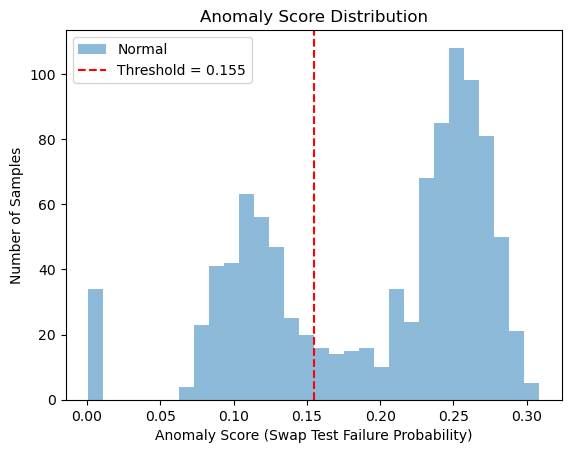

In [14]:
import matplotlib.pyplot as plt

# --- Histogram of scores ---
plt.hist(train_scores, bins=30, alpha=0.5, label='Normal')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()

Running inference: 100%|████████████████████| 2953/2953 [16:30<00:00,  2.98it/s]



All batches processed in 990.7131 seconds.
Model: 8f_qae_amplitude_ra3
Precision: 0.615
Accuracy: 0.116
Recall: 0.069
F1-Score: 0.125
Matrix: TP=11892, FP=7449, FN=159567, TN=10059
AUROC: 0.516
Data Loading + Inference Time (s): 990.7131s
Clf Report: precision    recall  f1-score   support

           0       0.06      0.57      0.11     17508
           1       0.61      0.07      0.12    171459

    accuracy                           0.12    188967
   macro avg       0.34      0.32      0.12    188967
weighted avg       0.56      0.12      0.12    188967


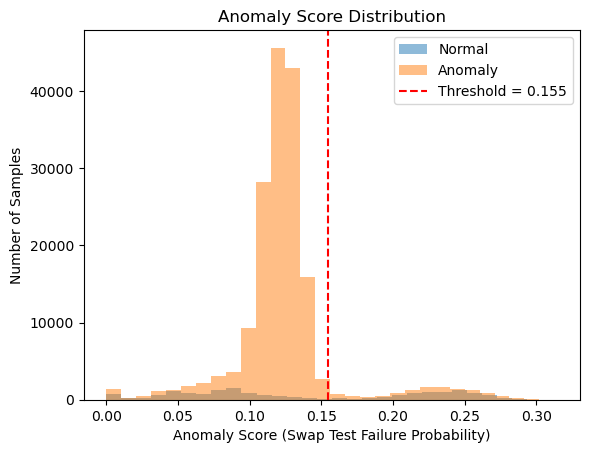

In [15]:
# Get predictions
# threshold -= 0.04

scores, elapsed_time = compute_anomaly_scores(
    ae,
    qnn,
    scaled_testing_data,
    trained_params,
    encoding_fn=dense_angle_encoding,
    batch_size=64
)

y_pred = (scores > threshold).astype(int)
y_true = np.array(testing_labels).astype(int)[:len(scores)]

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=scores,
    time=elapsed_time,
    threshold=threshold,  # same threshold used in predict
    model_name=model_name
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")

# --- Histogram of scores ---
plt.hist(scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()


Running inference: 100%|████████████████████| 2953/2953 [12:20<00:00,  3.99it/s]



All batches processed in 740.5719 seconds.
Model: 8f_qae_dense_ra
Precision: 0.036
Accuracy: 0.989
Recall: 0.061
F1-Score: 0.045
Matrix: TP=48, FP=1280, FN=738, TN=186901
AUROC: 0.111
Data Loading + Inference Time (s): 740.5719s
Clf Report: precision    recall  f1-score   support

           0       1.00      0.99      0.99    188181
           1       0.04      0.06      0.05       786

    accuracy                           0.99    188967
   macro avg       0.52      0.53      0.52    188967
weighted avg       0.99      0.99      0.99    188967


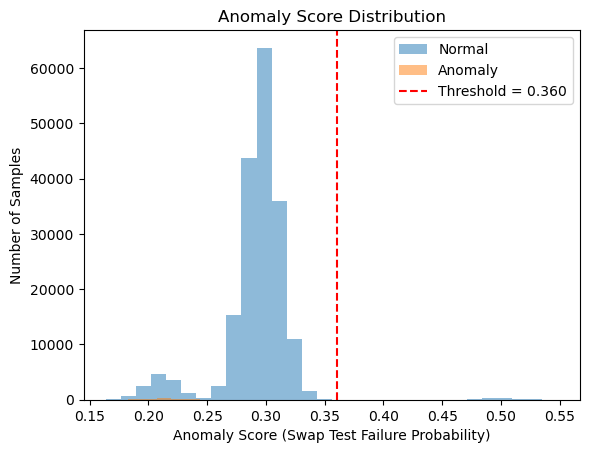

In [54]:
# Get predictions
v_scores, v_elapsed_time = compute_anomaly_scores(
    ae,
    qnn,
    scaled_validation_data,
    trained_params,
    encoding_fn=dense_angle_encoding,
    batch_size=64
)

y_pred = (v_scores > threshold).astype(int)
y_true = np.array(validation_labels).astype(int)[:len(v_scores)]

metrics = evaluate_model(
    y_true=y_true,
    y_pred=y_pred,
    scores=v_scores,
    time=v_elapsed_time,
    threshold=threshold,  # same threshold used in predict
    model_name=model_name
)

# Print clean table row for your notes
for k, v in metrics.items():
    print(f"{k}: {v}")

# --- Histogram of scores ---
plt.hist(v_scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(v_scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()
